# Beijing PM2.5: Exploratory Data Analysis

## 1. Introduction

This notebook explores hourly PM2.5 air pollution measurements in Beijing from 2010 to 2014, together with weather variables. The purpose is to understand the dataset, identify data-quality issues, investigate patterns in PM2.5 levels, and explore relationships that may be useful for time-series forecasting.

The analysis will investigate long-term trends, hourly patterns, relationships with weather conditions, lagged PM2.5 measurements, moving averages, and differences across wind directions. Each investigation will include the question being explored, the method used, a visualization, and an interpretation of the findings.

## 2. Dataset

The dataset is the Beijing PM2.5 Data dataset from the UCI Machine Learning Repository.

**Source:** https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data

The dataset contains hourly observations and includes the following information:

- **Date and time:** Year, month, day, and hour.
- **Target variable:** `pm2.5`, the measured fine particulate matter concentration.
- **Weather variables:** Dew point (`DEWP`), temperature (`TEMP`), atmospheric pressure (`PRES`), wind direction (`cbwd`), cumulative wind speed (`Iws`), and precipitation measurements (`Is` and `Ir`).

## 3. Analysis approach

We will begin by checking the dataset's dimensions, column types, missing values, date range, and timestamp consistency. We will then use exploratory data analysis to investigate at least five analytical questions.

Missing measurements will be examined before deciding how to handle them. We will not replace missing PM2.5 values with zero without justification, and we will distinguish observed findings from possible explanations.

Because this is time-series data, we will also examine chronological ordering and missing time intervals before calculating lagged features and moving averages. These checks will help us avoid misleading results and reduce the risk of data leakage.

# 4. Load and inspect the dataset

### Import libraries

In [52]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Locate and load the dataset

In [53]:
data_path = Path("../data/raw/PRSA_data_2010.1.1-2014.12.31.csv")

df = pd.read_csv(data_path, na_values=["NaN"])

print(f"Number of rows: {df.shape[0]:}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 43824
Number of columns: 13


### columns inspection and data quality

In [54]:
# preview the first 5 records

display(df.head())

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [55]:
# inspect column names and data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  str    
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), str(1)
memory usage: 4.3 MB


In [56]:
# Count missing values in each column

print("missing_summary:", df.isna().sum())

missing_summary: No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64


In [57]:
# Check for completely duplicated rows

print("Completely_duplicated_rows:", df.duplicated().sum())

Completely_duplicated_rows: 0


## 5. Timestamp, time range and frequency

In [58]:
# Combine the date and hour column into a single timestamp

df["timestamp"] = pd.to_datetime(
    df[["day", "month", "year", "hour"]]
)

df =df.sort_values("timestamp").reset_index(drop=True)

print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

First timestamp: 2010-01-01 00:00:00
Last timestamp: 2014-12-31 23:00:00


In [59]:
# Check time difference between consecutive records

time_diff = df["timestamp"].diff().value_counts()

print("Most common time differences between records:")
display(time_diff)

Most common time differences between records:


timestamp
0 days 01:00:00    43823
Name: count, dtype: int64

## 6. Statistical Summary of Numerical Variables

Before analyzing PM2.5 patterns, we examine the distributions of the main numerical measurements. Summary statistics help us understand their typical values, variability, and potential skewness or extreme values.

In [60]:
# Calculate the summary statistics

measurement_columns = [
    "pm2.5",
    "DEWP",
    "TEMP",
    "PRES",
    "Iws",
    "Is",
    "Ir",
]

summary = df[measurement_columns].describe().T

summary["median"] = df[measurement_columns].median()
summary["skewness"] = df[measurement_columns].skew()

display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,median,skewness
pm2.5,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,994.0,72.00,1.80
DEWP,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,28.0,2.00,-0.15
TEMP,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,42.0,14.00,-0.16
PRES,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1046.0,1016.00,0.10
Iws,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,585.6,5.37,4.30
Is,43824.0,0.05,0.76,0.00,0.00,0.00,0.00,27.0,0.00,19.48
Ir,43824.0,0.19,1.42,0.00,0.00,0.00,0.00,36.0,0.00,11.66


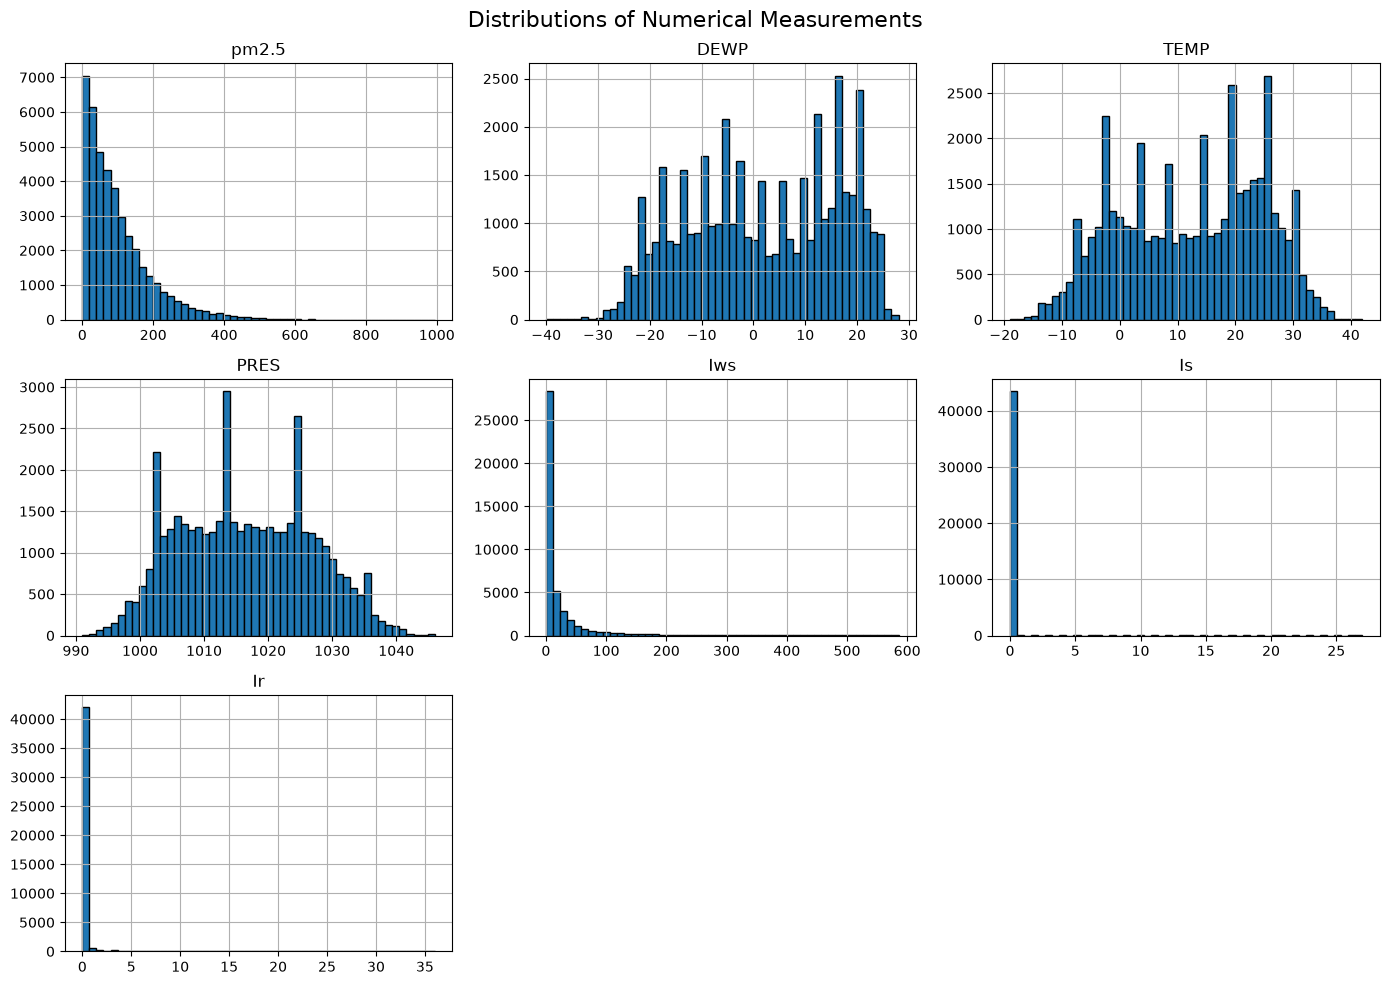

In [61]:
# Create histograms

import matplotlib.pyplot as plt

df[measurement_columns].hist(
    figsize=(14, 10),
    bins=50,
    edgecolor="black",
)

plt.suptitle(
    "Distributions of Numerical Measurements",
    fontsize=16,
)

plt.tight_layout()
plt.show()

The numerical variables have different distributions. PM2.5 and wind speed are strongly right-skewed, meaning most values are relatively low, but some extremely high observations raise their averages. PM2.5 has a mean of 98.61 and a median of 72, while wind speed has a mean of 23.89 and a median of 5.37. Temperature, dew point, and pressure have more balanced distributions, although they are not necessarily normally distributed. Snow and rain measurements are mostly zero. These differences are important when preparing data for modeling, and extreme values should be investigated rather than automatically removed.

### Missing-Value Analysis

The dataset contains missing PM2.5 measurements. Before deciding how to handle them, we examine how the missing values are distributed across time and how long consecutive periods of missing measurements last.

In [62]:
missing_by_year = df.groupby(
    df["timestamp"].dt.year
)["pm2.5"].agg(
    total_missing=lambda values: values.isna().sum(),
    missing_percentage=lambda values: values.isna().mean() * 100,
)

display(missing_by_year.round(2))

,total_missing,missing_percentage
timestamp,,
2010,669,7.64
2011,728,8.31
2012,489,5.57
2013,82,0.94
2014,99,1.13


#### Examine missing values by month and hour

In [63]:
missing_by_month = df.groupby(
    df["timestamp"].dt.month
)["pm2.5"].agg(
    total_missing=lambda values: values.isna().sum(),
    missing_percentage=lambda values: values.isna().mean() * 100,
)

display(missing_by_month.round(2))

,total_missing,missing_percentage
timestamp,,
1,249,6.69
2,11,0.33
3,164,4.41
4,195,5.42
5,111,2.98
6,195,5.42
7,73,1.96
8,383,10.30
9,267,7.42


In [64]:
missing_by_hour = df.groupby(
    df["timestamp"].dt.hour
)["pm2.5"].agg(
    total_missing=lambda values: values.isna().sum(),
    missing_percentage=lambda values: values.isna().mean() * 100,
)

display(missing_by_hour.round(2))

,total_missing,missing_percentage
timestamp,,
0,91,4.98
1,81,4.44
2,87,4.76
3,81,4.44
4,82,4.49
5,86,4.71
6,86,4.71
7,87,4.76
8,88,4.82


In [65]:
missing = df["pm2.5"].isna()

group_ids = missing.ne(missing.shift()).cumsum()

gap_lengths = (
    missing[missing]
    .groupby(group_ids[missing])
    .size()
)

print("Number of separate gaps:", len(gap_lengths))
print("Median gap length:", gap_lengths.median(), "hours")
print("Longest gap:", gap_lengths.max(), "hours")

Number of separate gaps: 214
Median gap length: 1.0 hours
Longest gap: 155 hours


In [66]:
gap_categories = pd.cut(
    gap_lengths,
    bins=[0, 3, 24, float("inf")],
    labels=["1–3 hours", "4–24 hours", "Over 24 hours"],
)

print(gap_categories.value_counts(sort=False))

pm2.5
1–3 hours        143
4–24 hours        51
Over 24 hours     20
Name: count, dtype: int64


The dataset contains 2,067 missing PM2.5 measurements out of 43,824 hourly observations (4.72%), while the other numerical variables have no missing values. Missingness varies across years and months, and the 214 gaps include some long periods, with the longest lasting 155 consecutive hours. Because interpolation across long gaps could produce misleading values, we preserve missing measurements in the processed dataset rather than replacing them with zero. For supervised training, we exclude rows without observed PM2.5 targets, leaving 41,757 usable target values. This preserves the original data while ensuring the model learns from actual measurements.

## 8. Analytical questions

The six questions below investigate trends, daily patterns, weather relationships, lagged values, moving averages and wind direction. Questions 4 and 5 use lagged features and moving averages, as the assignment requires.

### Question 1: How did the average PM2.5 concentration change from 2010 to 2014, and are there visible patterns across months?

for examining the monthly trend helps us understand how pollution levels vary over time. It may reveal longer-term changes or recurring seasonal patterns that could be useful when developing a time-series forecasting pipeline.

We will calculate the mean PM2.5 concentration for each calendar month and visualize the results using a line chart. Pandas excludes missing PM2.5 values when calculating the mean, so each monthly average will be based on available measurements. We will also check how many valid measurements contribute to each monthly average.

In [67]:
# Calculate monthly PM2.5 averages and available measurements
monthly_pm25 = (
    df.set_index("timestamp")["pm2.5"]
    .resample("MS")
    .agg(["mean", "count"])
)

monthly_pm25.columns = ["mean_pm25", "valid_measurements"]

display(monthly_pm25.head())

,mean_pm25,valid_measurements
timestamp,,
2010-01-01,90.442573,653
2010-02-01,97.233979,671
2010-03-01,94.100141,709
2010-04-01,80.029248,718
2010-05-01,86.899593,737


In [68]:
# Summarize the number of valid measurements per month
print("Monthly valid measurement counts:")
display(monthly_pm25["valid_measurements"].describe())

Monthly valid measurement counts:


count     60.000000
mean     695.950000
std       56.094782
min      468.000000
25%      672.000000
50%      715.000000
75%      737.000000
max      744.000000
Name: valid_measurements, dtype: float64

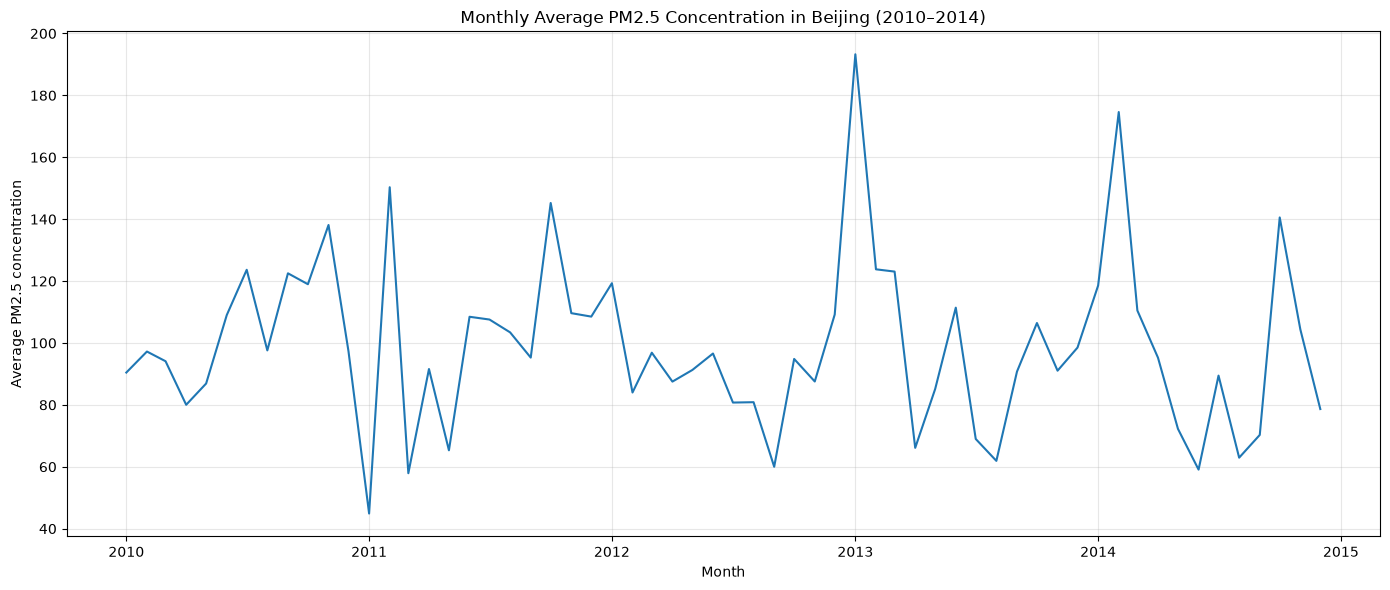

In [69]:
# Plot the monthly average PM2.5 concentration
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_pm25.index,
    monthly_pm25["mean_pm25"],
    linewidth=1.5
)

plt.title("Monthly Average PM2.5 Concentration in Beijing (2010–2014)")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 concentration")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Monthly average PM2.5 concentrations fluctuate considerably between 2010 and 2014, with some months exceeding 140 and a peak of approximately 193 in early 2013. Other months have much lower averages, sometimes between 45 and 70. This shows substantial variation in pollution levels over time, but the chart alone does not establish a consistent long-term trend or recurring seasonal pattern. We should also consider differences in the number of valid measurements contributing to each monthly average. Overall, the results suggest that temporal patterns are worth investigating further.

### Question 2: How does the average PM2.5 concentration change across the 24 hours of a day?

Hourly patterns may reveal recurring changes in pollution levels throughout the day. Identifying these patterns can help us decide whether the hour of the day should be included as a feature in a forecasting pipeline.

We will group the available PM2.5 measurements by hour, calculate the mean for each hour from 0 to 23, and visualize the results using a line chart. We will also count the valid observations contributing to each hourly average.

In [70]:
# Calculate average PM2.5 concentration for each hour of the day
hourly_pm25 = (
    df.groupby("hour")["pm2.5"]
    .agg(["mean", "count"])
)

hourly_pm25.columns = ["mean_pm25", "valid_measurements"]

display(hourly_pm25)

,mean_pm25,valid_measurements
hour,,
0,113.390202,1735
1,113.698567,1745
2,110.323174,1739
3,108.042980,1745
4,104.080275,1744
5,100.013218,1740
6,96.882759,1740
7,96.024727,1739
8,95.907940,1738


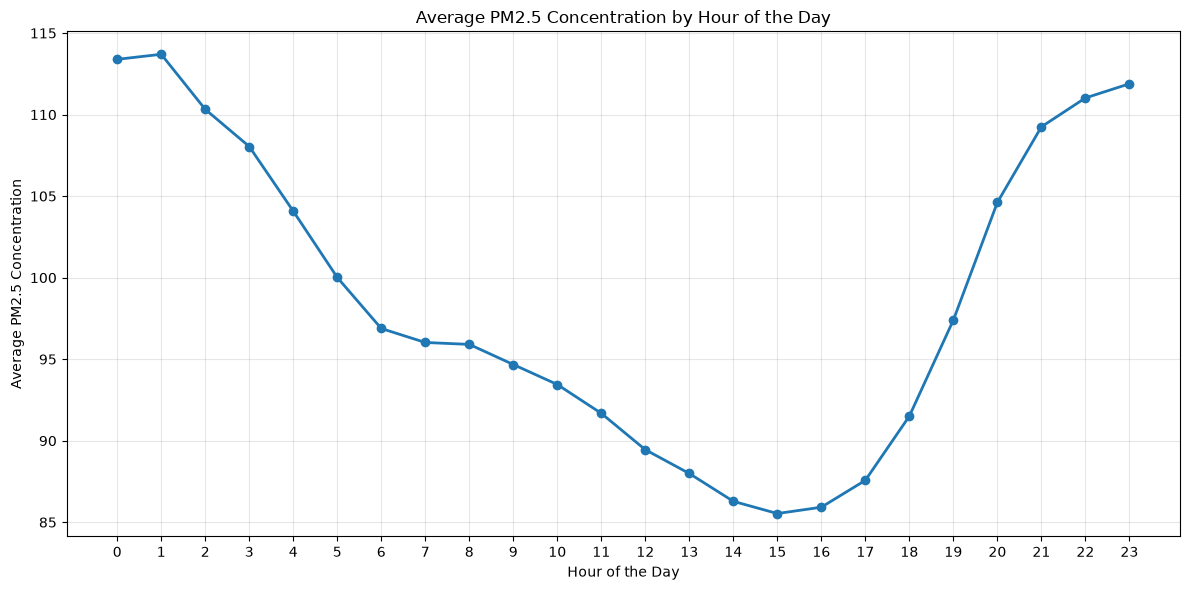

In [71]:
# Plot the average concentration by hour
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_pm25.index,
    hourly_pm25["mean_pm25"],
    marker="o",
    linewidth=2
)

plt.title("Average PM2.5 Concentration by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Average PM2.5 concentrations vary throughout the day. The highest average occurs at 01:00 (113.70), while the lowest occurs at 15:00 (85.53). Concentrations generally decline during the morning and early afternoon before rising again in the evening, reaching approximately 111.89 by 23:00. The difference between the highest and lowest hourly averages is about 28.16. This suggests that the hour of the day could be a useful feature for forecasting, although the pattern does not necessarily occur every day or explain what causes the changes.

### Question 3: What relationships exist between PM2.5 concentration and temperature, dew point, and atmospheric pressure?

Weather conditions may be associated with changes in air pollution. Investigating these relationships helps us understand the dataset and identify weather variables that may be useful for time-series forecasting.


In [72]:
# Select PM2.5 and numerical weather variables
weather_columns = ["pm2.5", "TEMP", "DEWP", "PRES"]

weather_data = df[weather_columns]

# Calculate pairwise correlations
correlation_matrix = weather_data.corr()

display(correlation_matrix)

,pm2.5,TEMP,DEWP,PRES
pm2.5,1.000000,-0.090534,0.171423,-0.047282
TEMP,-0.090534,1.000000,0.824633,-0.826690
DEWP,0.171423,0.824633,1.000000,-0.778346
PRES,-0.047282,-0.826690,-0.778346,1.000000


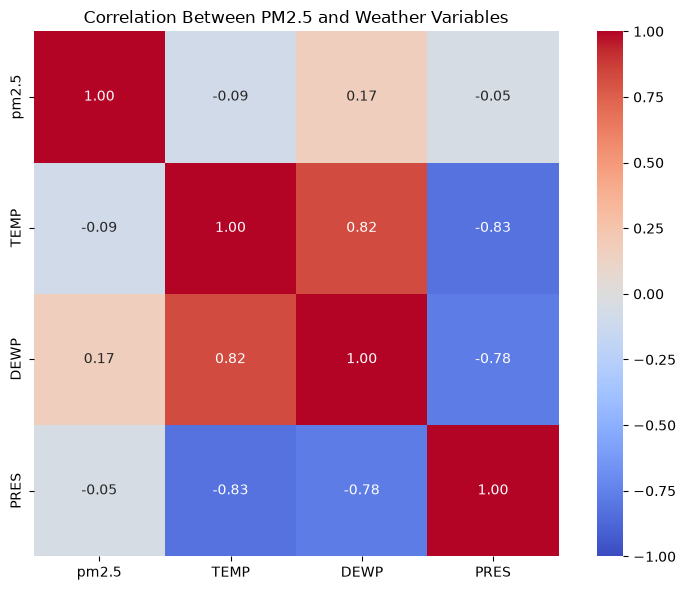

In [73]:
# Visualize the correlation matrix

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    square=True
)

plt.title("Correlation Between PM2.5 and Weather Variables")
plt.tight_layout()
plt.show()

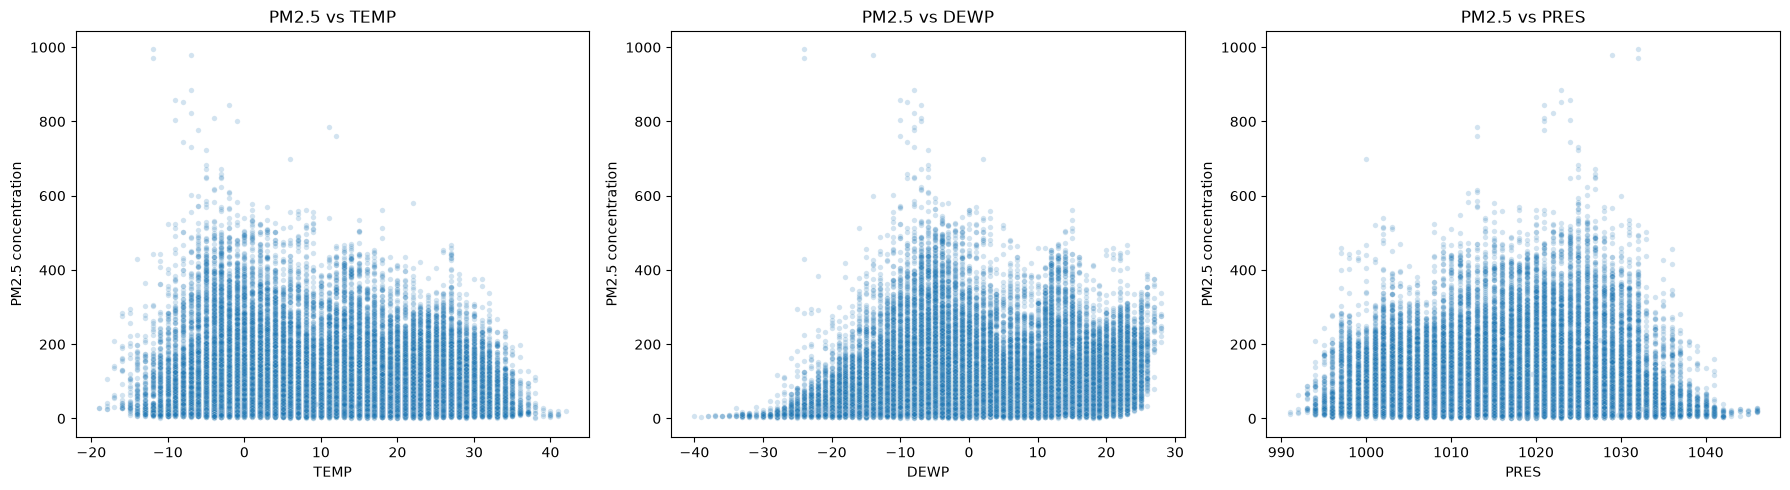

In [74]:
# Examine the relationships with scatter plots

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

weather_variables = ["TEMP", "DEWP", "PRES"]

for ax, variable in zip(axes, weather_variables):
    sns.scatterplot(
        data=df,
        x=variable,
        y="pm2.5",
        alpha=0.2,
        s=15,
        ax=ax
    )

    ax.set_title(f"PM2.5 vs {variable}")
    ax.set_xlabel(variable)
    ax.set_ylabel("PM2.5 concentration")

plt.tight_layout()
plt.show()

Temperature, dew point, and atmospheric pressure have weak linear correlations with PM2.5: approximately -0.09, +0.17, and -0.05, respectively. Dew point has the strongest individual correlation, but the relationship is still weak. The weather variables are more strongly correlated with one another, particularly temperature and dew point (+0.82) and temperature and pressure (-0.83). This may be relevant when selecting model features. Overall, no single weather variable strongly explains PM2.5 variation through a linear relationship, although nonlinear and seasonal relationships may still exist.

### Question 4: How strongly are current PM2.5 concentrations associated with measurements from one hour and 24 hours earlier?

Time-series forecasting uses information from previous observations to help predict future values. If PM2.5 measurements are associated with recent measurements, lagged features may be useful predictors.

We will create one-hour and 24-hour lagged PM2.5 features, calculate their correlations with the current measurements, and visualize the relationships using scatter plots. We will exclude rows where the current or lagged PM2.5 value is missing.

In [75]:
# Create lagged PM2.5 features
df["pm25_lag_1h"] = df["pm2.5"].shift(1)
df["pm25_lag_24h"] = df["pm2.5"].shift(24)

# Display a sample of the current and lagged values
display(
    df[["timestamp", "pm2.5", "pm25_lag_1h", "pm25_lag_24h"]].head(30)
)

,timestamp,pm2.5,pm25_lag_1h,pm25_lag_24h
0,2010-01-01 00:00:00,NaN,NaN,NaN
1,2010-01-01 01:00:00,NaN,NaN,NaN
2,2010-01-01 02:00:00,NaN,NaN,NaN
3,2010-01-01 03:00:00,NaN,NaN,NaN
4,2010-01-01 04:00:00,NaN,NaN,NaN
5,2010-01-01 05:00:00,NaN,NaN,NaN
6,2010-01-01 06:00:00,NaN,NaN,NaN
7,2010-01-01 07:00:00,NaN,NaN,NaN
8,2010-01-01 08:00:00,NaN,NaN,NaN
9,2010-01-01 09:00:00,NaN,NaN,NaN


In [76]:
# Calculate the correlations

lag_correlations = df[
    ["pm2.5", "pm25_lag_1h", "pm25_lag_24h"]
].corr()

display(lag_correlations)

print(
    "Correlation with previous hour:",
    df["pm2.5"].corr(df["pm25_lag_1h"])
)

print(
    "Correlation with previous 24 hours:",
    df["pm2.5"].corr(df["pm25_lag_24h"])
)

,pm2.5,pm25_lag_1h,pm25_lag_24h
pm2.5,1.000000,0.965297,0.398151
pm25_lag_1h,0.965297,1.000000,0.412680
pm25_lag_24h,0.398151,0.412680,1.000000


Correlation with previous hour: 0.9652970491995948
Correlation with previous 24 hours: 0.39815091484923376


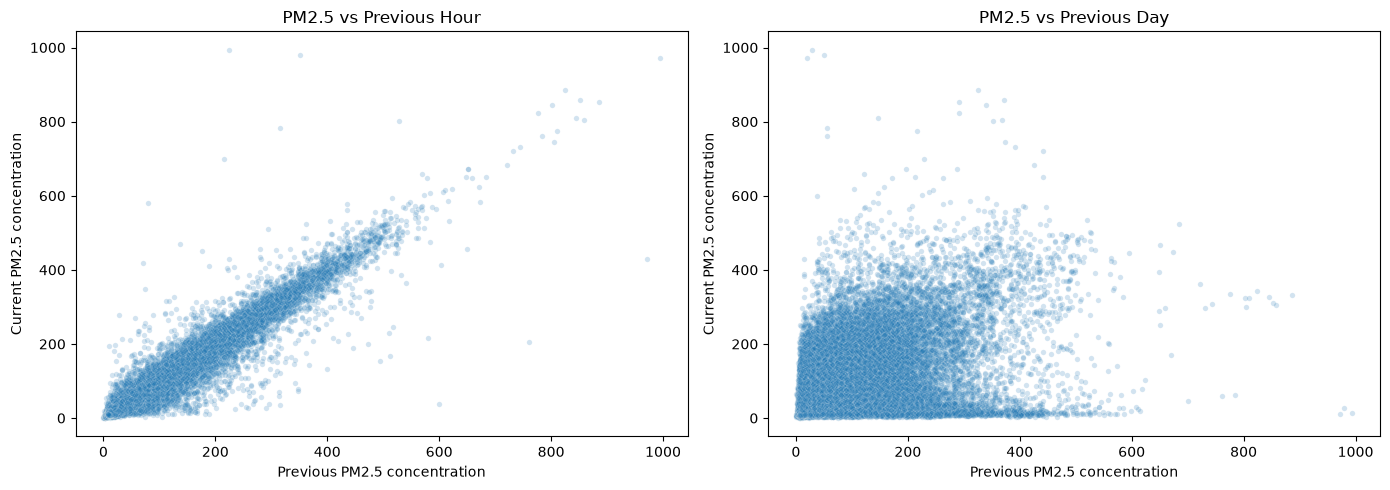

In [77]:
# Visualize both relationships

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lag_features = [
    ("pm25_lag_1h", "PM2.5 vs Previous Hour"),
    ("pm25_lag_24h", "PM2.5 vs Previous Day")
]

for ax, (lag_column, title) in zip(axes, lag_features):
    plot_data = df[[lag_column, "pm2.5"]].dropna()

    sns.scatterplot(
        data=plot_data,
        x=lag_column,
        y="pm2.5",
        alpha=0.2,
        s=15,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Previous PM2.5 concentration")
    ax.set_ylabel("Current PM2.5 concentration")

plt.tight_layout()
plt.show()

PM2.5 has a very strong positive correlation with its value one hour earlier (0.9653), suggesting that pollution concentrations tend to remain similar between consecutive hours. The correlation with the value 24 hours earlier is weaker (0.3982), showing that the previous day's measurement is less strongly associated with the current measurement. These findings suggest that recent PM2.5 readings could be useful features for forecasting. However, their actual predictive value must be confirmed through time-based model evaluation.

### Question 5: How do short-term and daily moving averages compare with hourly PM2.5 measurements?

Hourly PM2.5 concentrations can fluctuate considerably, making it difficult to identify broader patterns. Moving averages help smooth these fluctuations by calculating average concentrations over a specified period.

In this section, we calculate 7-hour and 24-hour moving averages to compare short-term and daily pollution patterns. We use previous observations only, ensuring that each moving average does not include measurements from the current or future hours.

In [78]:
# Calculate moving averages using previous observations only
df = df.sort_values("timestamp").reset_index(drop=True)

df["pm25_ma_7h"] = (
    df["pm2.5"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

df["pm25_ma_24h"] = (
    df["pm2.5"]
    .shift(1)
    .rolling(window=24, min_periods=24)
    .mean()
)


In [79]:
# Display the original measurements and moving averages
display(
    df[
        ["timestamp", "pm2.5", "pm25_ma_7h", "pm25_ma_24h"]
    ].head(35)
)

,timestamp,pm2.5,pm25_ma_7h,pm25_ma_24h
0,2010-01-01 00:00:00,NaN,NaN,NaN
1,2010-01-01 01:00:00,NaN,NaN,NaN
2,2010-01-01 02:00:00,NaN,NaN,NaN
3,2010-01-01 03:00:00,NaN,NaN,NaN
4,2010-01-01 04:00:00,NaN,NaN,NaN
5,2010-01-01 05:00:00,NaN,NaN,NaN
6,2010-01-01 06:00:00,NaN,NaN,NaN
7,2010-01-01 07:00:00,NaN,NaN,NaN
8,2010-01-01 08:00:00,NaN,NaN,NaN
9,2010-01-01 09:00:00,NaN,NaN,NaN


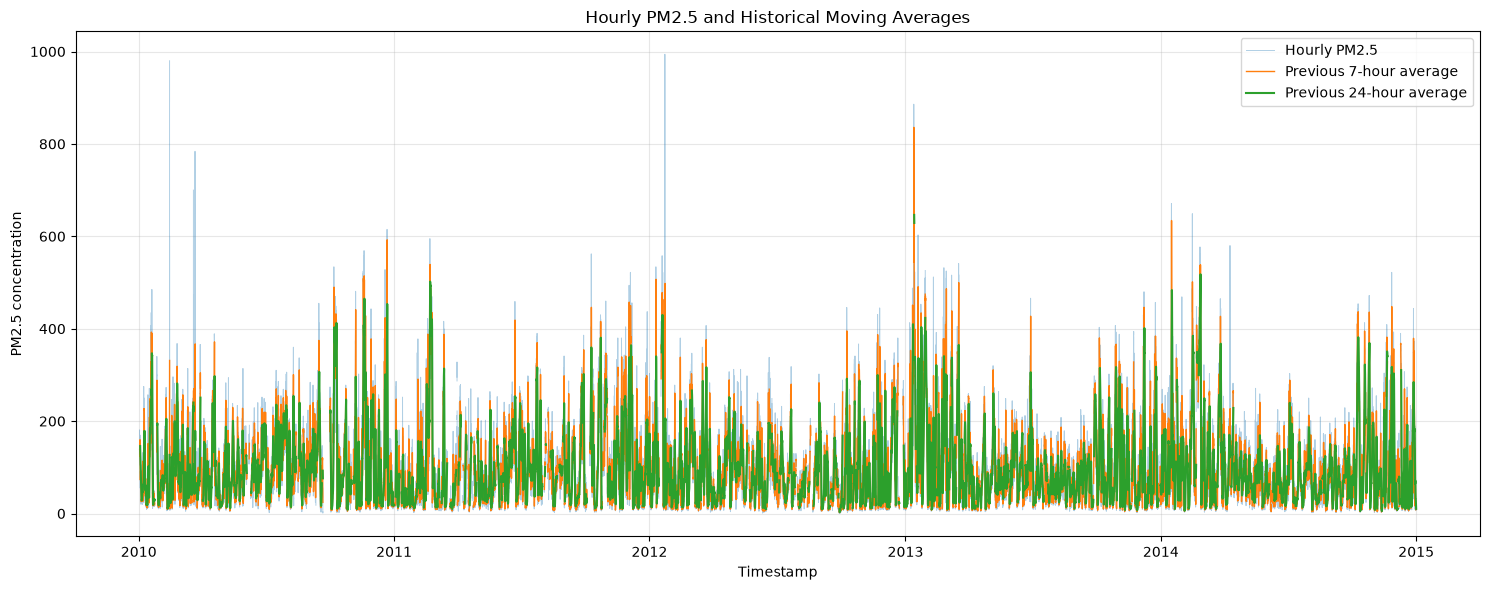

In [80]:
# Visualize the results

plt.figure(figsize=(15, 6))

plt.plot(
    df["timestamp"],
    df["pm2.5"],
    label="Hourly PM2.5",
    alpha=0.35,
    linewidth=0.7
)

plt.plot(
    df["timestamp"],
    df["pm25_ma_7h"],
    label="Previous 7-hour average",
    linewidth=1
)

plt.plot(
    df["timestamp"],
    df["pm25_ma_24h"],
    label="Previous 24-hour average",
    linewidth=1.5
)

plt.title("Hourly PM2.5 and Historical Moving Averages")
plt.xlabel("Timestamp")
plt.ylabel("PM2.5 concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [81]:
# Compare the variability numerically

moving_average_summary = df[
    ["pm2.5", "pm25_ma_7h", "pm25_ma_24h"]
].std()

moving_average_summary = moving_average_summary.rename({
    "pm2.5": "Hourly PM2.5",
    "pm25_ma_7h": "Previous 7-hour average",
    "pm25_ma_24h": "Previous 24-hour average"
})

display(moving_average_summary.to_frame(name="Standard deviation"))

,Standard deviation
Hourly PM2.5,92.050387
Previous 7-hour average,87.625603
Previous 24-hour average,77.172017


Moving averages smooth short-term fluctuations in PM2.5 concentrations. The 7-hour moving average responds to relatively recent changes, while the 24-hour moving average produces a smoother view of broader patterns. Their standard deviations are 87.63 and 77.17, respectively, compared with 92.05 for the original hourly measurements. This confirms that longer moving-average windows reduce variability. These features may help a forecasting model summarize recent pollution levels, but their usefulness must be tested using an appropriate time-series validation approach.

### Question 6: How does wind direction relate to PM2.5 concentration?

Wind direction may be associated with differences in air pollution because air movement can transport pollutants from one location to another. In this section, we compare PM2.5 concentrations across the wind direction categories recorded in the dataset.

We calculate the average PM2.5 concentration and the number of valid measurements for each category, then visualize the results to identify potential differences. This analysis explores associations and does not establish that wind direction alone causes changes in pollution.

In [82]:
# Count observations in each wind direction category
display(df["cbwd"].value_counts(dropna=False))

cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64

In [83]:
# Compare PM2.5 concentrations across wind directions
wind_pm25 = (
    df.groupby("cbwd", dropna=False)["pm2.5"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

wind_pm25.columns = [
    "mean_pm25",
    "median_pm25",
    "valid_measurements"
]

display(wind_pm25)

,mean_pm25,median_pm25,valid_measurements
cbwd,,,
cv,126.151945,98.0,8944
SE,110.821588,91.0,14573
NE,90.177670,55.0,4756
NW,70.127633,31.0,13484


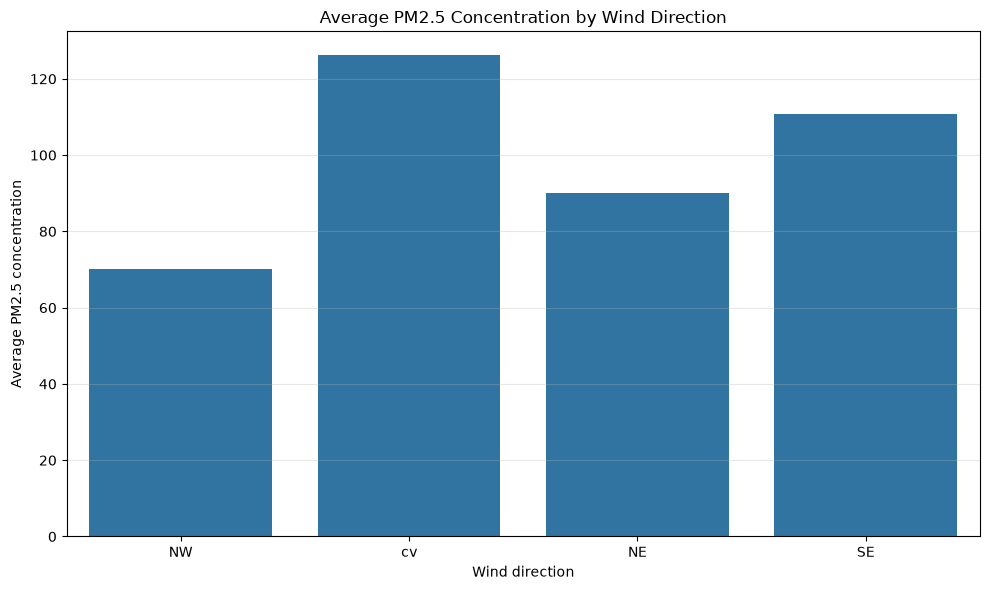

In [84]:
# Visualize the results

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="cbwd",
    y="pm2.5",
    errorbar=None
)

plt.title("Average PM2.5 Concentration by Wind Direction")
plt.xlabel("Wind direction")
plt.ylabel("Average PM2.5 concentration")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

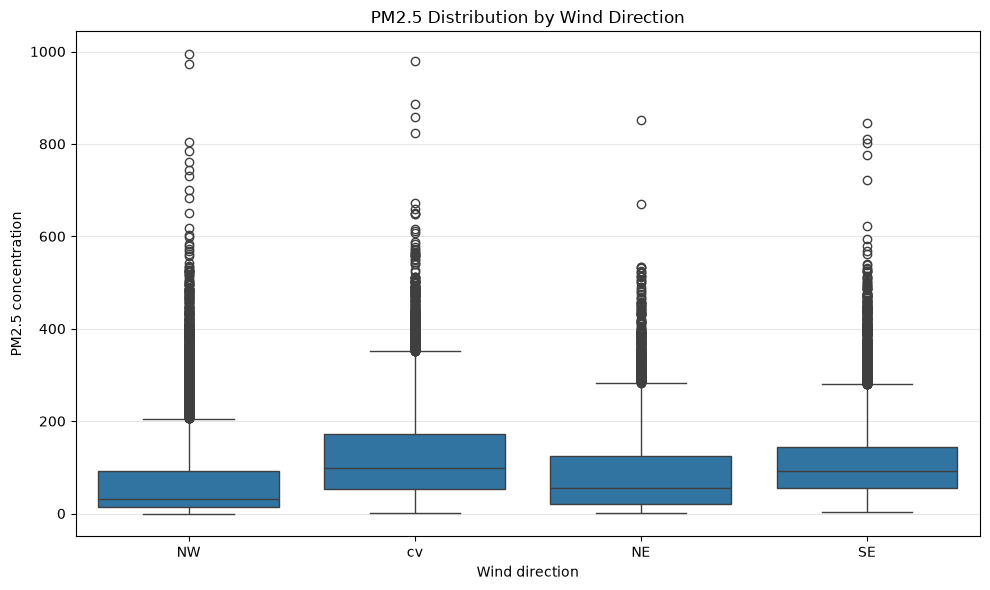

In [85]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="cbwd",
    y="pm2.5"
)

plt.title("PM2.5 Distribution by Wind Direction")
plt.xlabel("Wind direction")
plt.ylabel("PM2.5 concentration")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Average PM2.5 concentrations differ across wind direction categories. Calm or variable conditions (CV) have the highest average at 126.15, followed by south-east winds (SE) at 110.82 and north-east winds (NE) at 90.18. North-west winds (NW) have the lowest average at 70.13, giving a difference of approximately 56.02 between the highest and lowest categories. These results suggest an association between wind conditions and pollution levels, but they do not prove that wind direction causes the differences. Other factors, including weather, season, and pollution sources, may also contribute.